In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [48]:
df = pd.read_csv("../data/diabetic_data.csv", na_values="?", low_memory=False)

print("Shape:", df.shape)
df.head()

Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData types:")
print(df.dtypes.value_counts())

Rows: 101766
Columns: 50

Data types:
str      37
int64    13
Name: count, dtype: int64


In [5]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [6]:
missing_count = df.isnull().sum()

missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percent", ascending=False)

missing_summary

,missing_count,missing_percent
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322


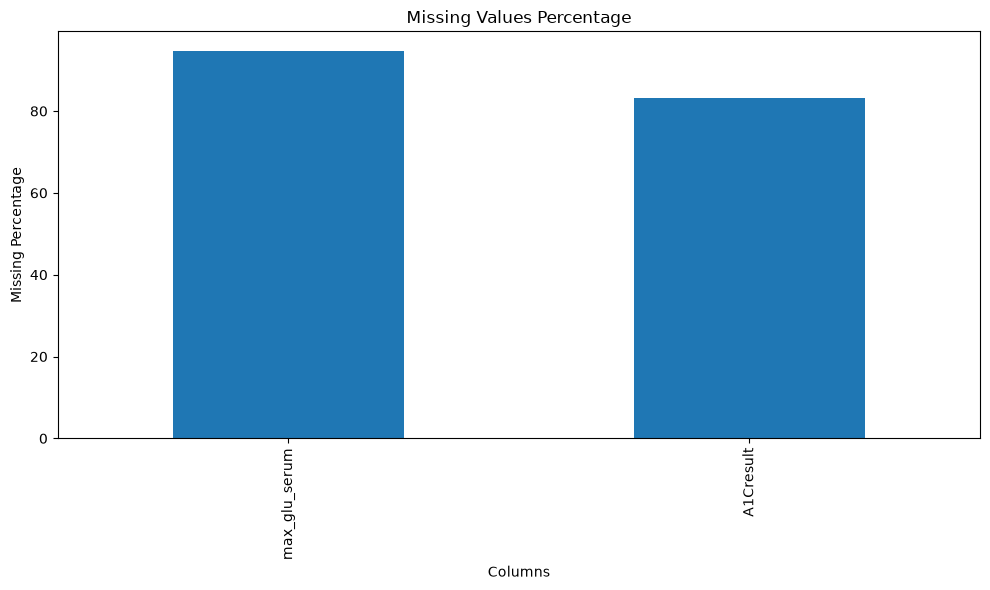

In [7]:
plt.figure(figsize=(10, 6))

missing_summary["missing_percent"].plot(kind="bar")

plt.title("Missing Values Percentage")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [8]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numeric_cols.tolist())

Numerical columns:
['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [10]:
categorical_cols = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_cols.tolist())

print("\nNumber of categorical columns:", len(categorical_cols))

Categorical columns:
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Number of categorical columns: 37


C:\Users\HP\AppData\Local\Temp\ipykernel_7884\1647533550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [11]:
target_counts = df["readmitted"].value_counts()

print(target_counts)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [12]:
target_percent = df["readmitted"].value_counts(normalize=True) * 100

print(target_percent)

readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64


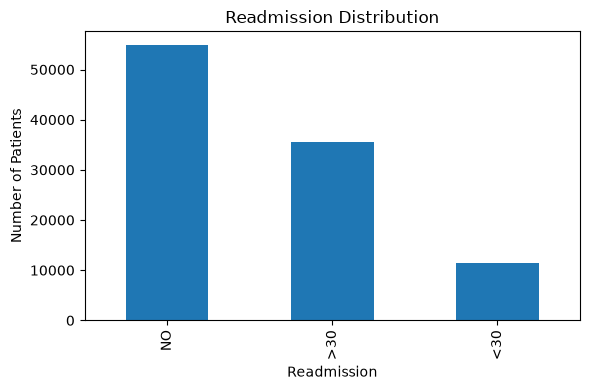

In [13]:
plt.figure(figsize=(6, 4))

df["readmitted"].value_counts().plot(kind="bar")

plt.title("Readmission Distribution")
plt.xlabel("Readmission")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [14]:
print(df["gender"].value_counts())

print("\nPercentages:")
print(df["gender"].value_counts(normalize=True) * 100)

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Percentages:
gender
Female             53.758623
Male               46.238429
Unknown/Invalid     0.002948
Name: proportion, dtype: float64


In [15]:
print(
    df.groupby("gender")["readmitted"]
      .value_counts(normalize=True) * 100
)

gender           readmitted
Female           NO             53.078160
                 >30            35.676683
                 <30            11.245156
Male             NO             54.878334
                 >30            34.060142
                 <30            11.061524
Unknown/Invalid  NO            100.000000
Name: proportion, dtype: float64


In [16]:
print(df["age"].value_counts())

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64


In [17]:
age_readmission = (
    df.groupby("age")["readmitted"]
      .value_counts(normalize=True) * 100
)

print(age_readmission)

age       readmitted
[0-10)    NO            81.987578
          >30           16.149068
          <30            1.863354
[10-20)   NO            61.794501
          >30           32.416787
          <30            5.788712
[20-30)   NO            54.978877
          >30           30.778515
          <30           14.242607
[30-40)   NO            57.324503
          >30           31.443709
          <30           11.231788
[40-50)   NO            55.549819
          >30           33.846154
          <30           10.604027
[50-60)   NO            56.044274
          >30           34.289522
          <30            9.666203
[60-70)   NO            53.747276
          >30           35.124316
          <30           11.128408
[70-80)   NO            51.879699
          >30           36.347246
          <30           11.773055
[80-90)   NO            51.729953
          >30           36.186544
          <30           12.083503
[90-100)  NO            59.971357
          >30           28.

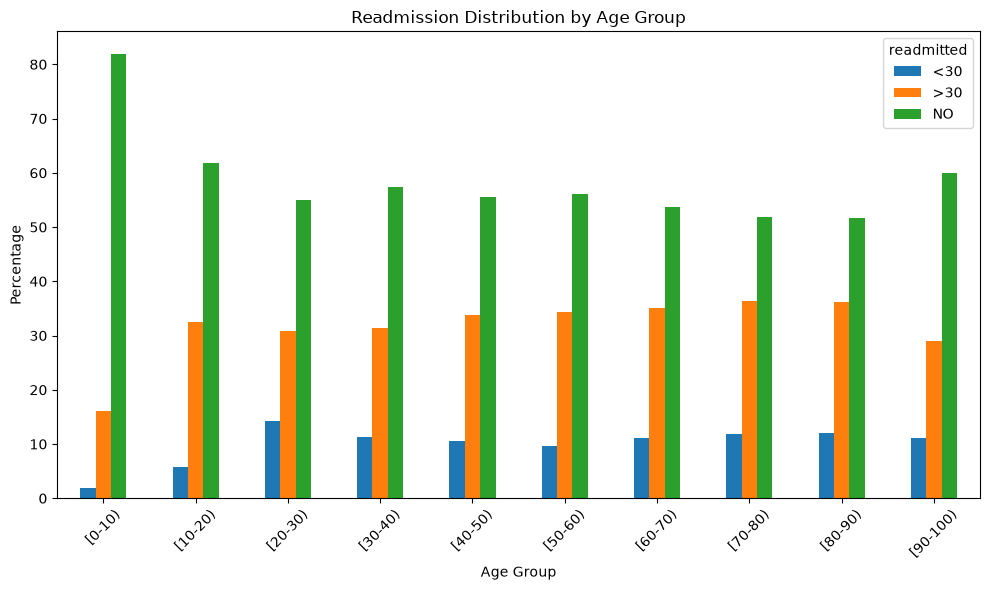

In [18]:
age_readmission.unstack().plot(kind="bar", figsize=(10, 6))

plt.title("Readmission Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [19]:
print(df["race"].value_counts())

print("\nReadmission by race:")
print(
    df.groupby("race")["readmitted"]
      .value_counts(normalize=True) * 100
)

race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

Readmission by race:
race             readmitted
?                NO            68.059833
                 >30           23.669160
                 <30            8.271007
AfricanAmerican  NO            54.247788
                 >30           34.534097
                 <30           11.218116
Asian            NO            64.742590
                 >30           25.117005
                 <30           10.140406
Caucasian        NO            53.066400
                 >30           35.643044
                 <30           11.290556
Hispanic         NO            58.075601
                 >30           31.516937
                 <30           10.407462
Other            NO            60.756972
                 >30           29.614874
                 <30            9.628154
Name: proportion, dtype: float6

readmitted             <30        >30         NO
race                                            
?                 8.271007  23.669160  68.059833
AfricanAmerican  11.218116  34.534097  54.247788
Asian            10.140406  25.117005  64.742590
Caucasian        11.290556  35.643044  53.066400
Hispanic         10.407462  31.516937  58.075601
Other             9.628154  29.614874  60.756972


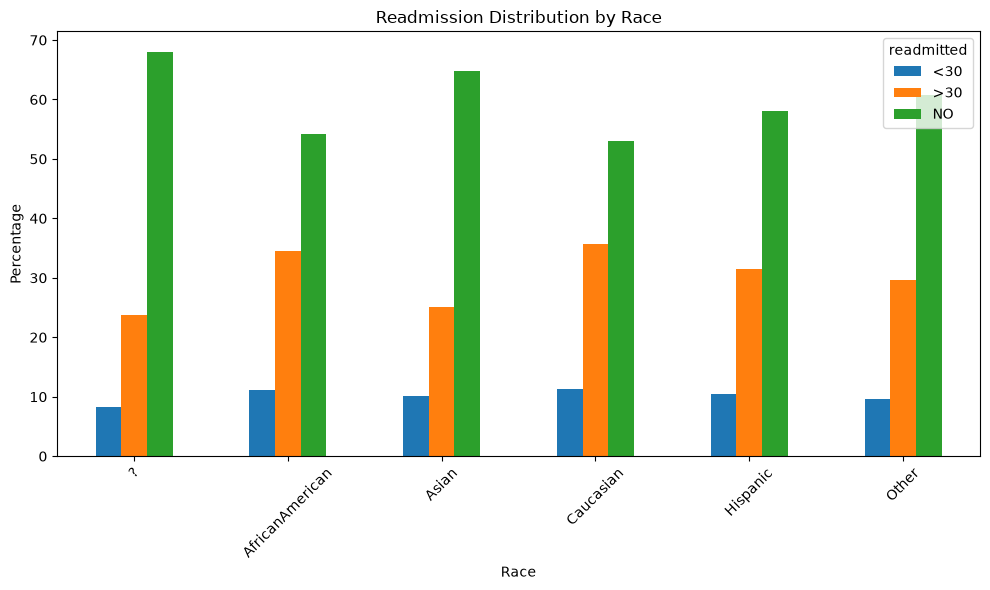

In [47]:
race_readmission = (
    df.groupby("race")["readmitted"]
      .value_counts(normalize=True)
      .unstack() * 100
)

print(race_readmission)

race_readmission.plot(kind="bar", figsize=(10, 6))

plt.title("Readmission Distribution by Race")
plt.xlabel("Race")
plt.ylabel("Percentage")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
print(df["weight"].value_counts())

print("\nWeight missing percentage:")
print(df["weight"].isna().mean() * 100)

weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

Weight missing percentage:
0.0


In [23]:
weight_readmission = (
    df.groupby("weight")["readmitted"]
      .value_counts(normalize=True) * 100
)

print(weight_readmission)

weight     readmitted
>200       >30           100.000000
?          NO             54.311193
           >30            34.529112
           <30            11.159695
[0-25)     >30            64.583333
           NO             18.750000
           <30            16.666667
[100-125)  >30            46.720000
           NO             42.560000
           <30            10.720000
[125-150)  >30            47.586207
           NO             44.137931
           <30             8.275862
[150-175)  NO             45.714286
           >30            45.714286
           <30             8.571429
[175-200)  >30            45.454545
           NO             45.454545
           <30             9.090909
[25-50)    NO             48.453608
           >30            43.298969
           <30             8.247423
[50-75)    NO             44.927536
           >30            43.366778
           <30            11.705686
[75-100)   >30            49.625749
           NO             38.922156
      

In [24]:
print(df["payer_code"].value_counts())

payer_code
?     40256
MC    32439
HM     6274
SP     5007
BC     4655
MD     3532
CP     2533
UN     2448
CM     1937
OG     1033
PO      592
DM      549
CH      146
WC      135
OT       95
MP       79
SI       55
FR        1
Name: count, dtype: int64


In [25]:
print(
    "Missing percentage:",
    df["payer_code"].isna().mean() * 100
)

Missing percentage: 0.0


In [26]:
payer_readmission = (
    df.groupby("payer_code")["readmitted"]
      .value_counts(normalize=True) * 100
)

print(payer_readmission)

payer_code  readmitted
?           NO             54.155902
            >30            34.350159
            <30            11.493939
BC          NO             62.900107
            >30            27.948443
            <30             9.151450
CH          NO             68.493151
            >30            22.602740
            <30             8.904110
CM          NO             55.653072
            >30            34.124935
            <30            10.221993
CP          NO             60.718516
            >30            30.833004
            <30             8.448480
DM          NO             48.269581
            >30            40.072860
            <30            11.657559
FR          NO            100.000000
HM          NO             52.757412
            >30            36.978004
            <30            10.264584
MC          NO             51.317858
            >30            36.937020
            <30            11.745122
MD          NO             52.576444
            >30

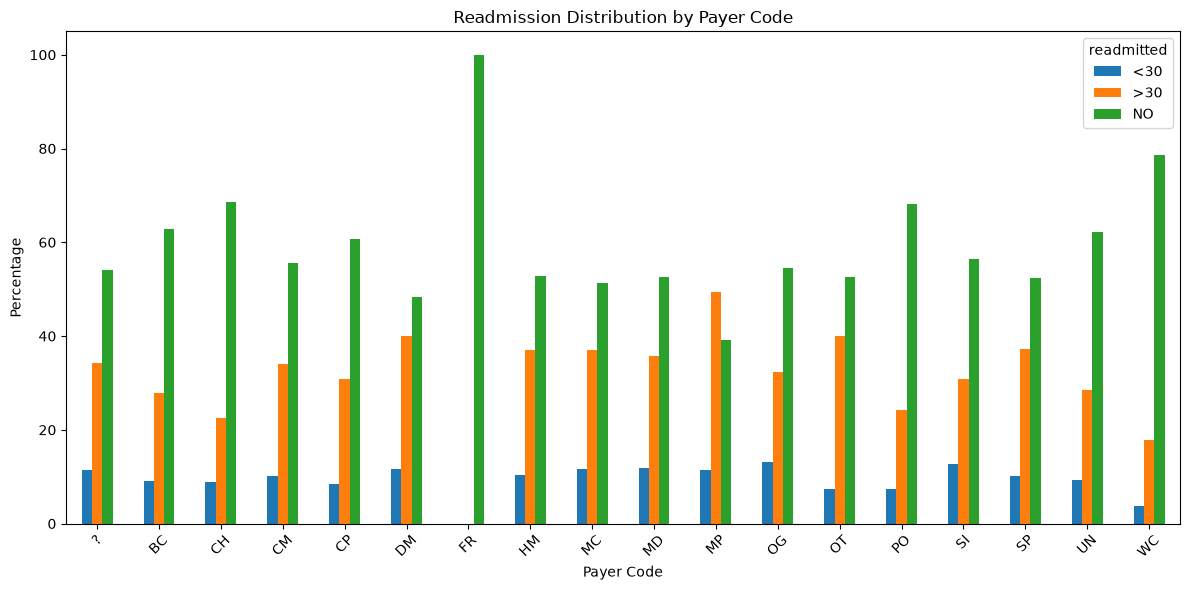

In [27]:
payer_readmission.unstack().plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Readmission Distribution by Payer Code")
plt.xlabel("Payer Code")
plt.ylabel("Percentage")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [28]:
print(df["medical_specialty"].value_counts())

medical_specialty
?                         49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7440
Cardiology                 5352
                          ...  
Dermatology                   1
SportsMedicine                1
Speech                        1
Perinatology                  1
Neurophysiology               1
Name: count, Length: 73, dtype: int64


In [29]:
print(
    "Missing percentage:",
    df["medical_specialty"].isna().mean() * 100
)

Missing percentage: 0.0


In [30]:
df["medical_specialty"].value_counts().head(15)

medical_specialty
?                                  49949
InternalMedicine                   14635
Emergency/Trauma                    7565
Family/GeneralPractice              7440
Cardiology                          5352
Surgery-General                     3099
Nephrology                          1613
Orthopedics                         1400
Orthopedics-Reconstructive          1233
Radiologist                         1140
Pulmonology                          871
Psychiatry                           854
Urology                              685
ObstetricsandGynecology              671
Surgery-Cardiovascular/Thoracic      652
Name: count, dtype: int64

In [31]:
specialty_readmission = (
    df.groupby("medical_specialty")["readmitted"]
      .value_counts(normalize=True) * 100
)

print(specialty_readmission)

medical_specialty     readmitted
?                     NO            51.956996
                      >30           36.469199
                      <30           11.573805
AllergyandImmunology  <30           42.857143
                      >30           42.857143
                                      ...    
SurgicalSpecialty     >30           27.272727
                      <30            6.060606
Urology               NO            63.065693
                      >30           27.007299
                      <30            9.927007
Name: proportion, Length: 191, dtype: float64


In [32]:
print(df["time_in_hospital"].describe())

count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64


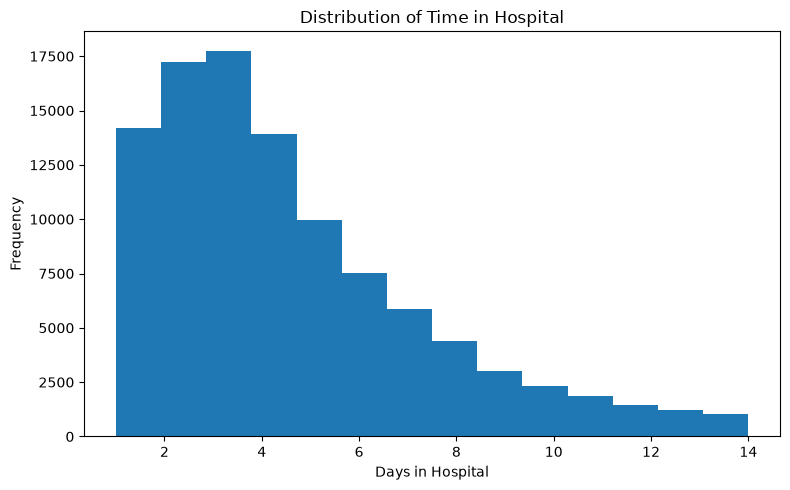

In [33]:
plt.figure(figsize=(8, 5))

df["time_in_hospital"].plot(kind="hist", bins=14)

plt.title("Distribution of Time in Hospital")
plt.xlabel("Days in Hospital")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [34]:
print(
    df.groupby("time_in_hospital")["readmitted"]
      .value_counts(normalize=True) * 100
)

time_in_hospital  readmitted
1                 NO            60.353322
                  >30           31.468187
                  <30            8.178491
2                 NO            55.695541
                  >30           34.364840
                  <30            9.939619
3                 NO            55.063077
                  >30           34.270106
                  <30           10.666817
4                 NO            51.824188
                  >30           36.368860
                  <30           11.806952
5                 NO            51.986755
                  >30           35.982340
                  <30           12.030905
6                 NO            50.868815
                  >30           36.543308
                  <30           12.587876
7                 NO            50.930193
                  >30           36.234852
                  <30           12.834955
8                 NO            49.578684
                  >30           36.187657
     

In [35]:
utilization_cols = [
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

df[utilization_cols].describe()

,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


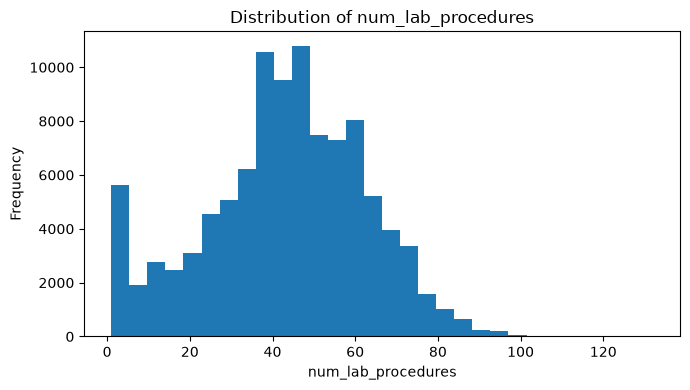

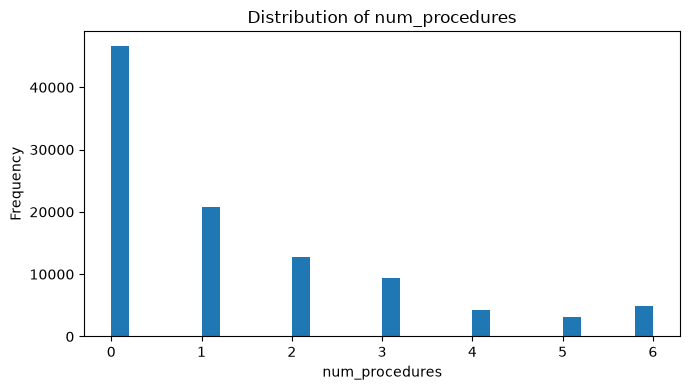

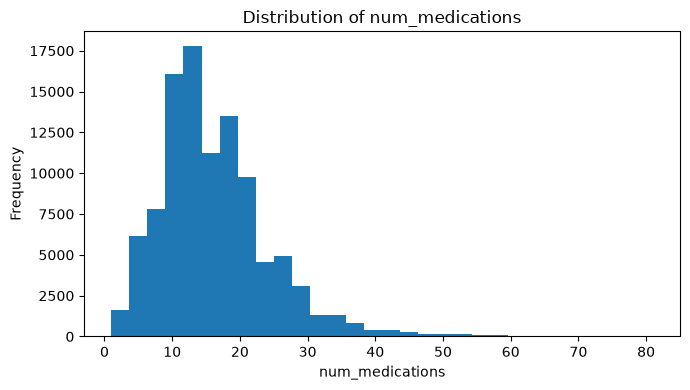

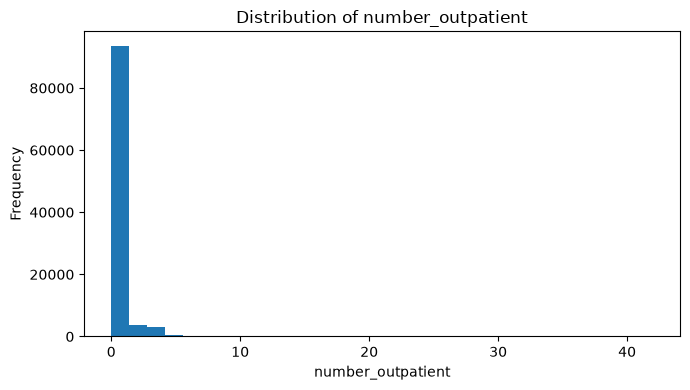

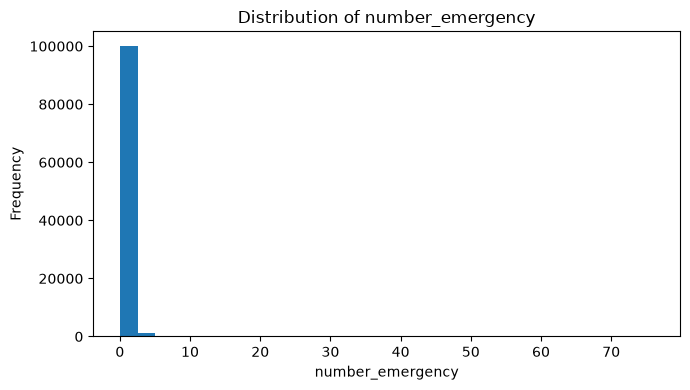

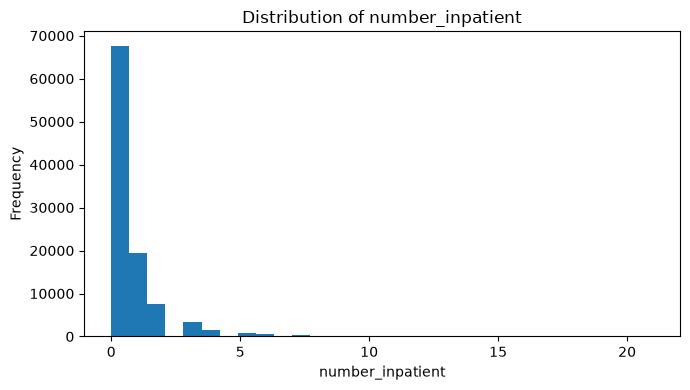

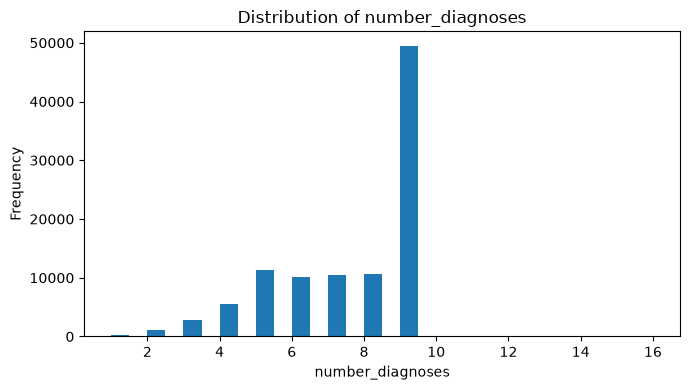

In [36]:
for col in utilization_cols:
    plt.figure(figsize=(7, 4))
    df[col].plot(kind="hist", bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [37]:
print("Max glucose:")
print(df["max_glu_serum"].value_counts())

print("\nA1C:")
print(df["A1Cresult"].value_counts())

Max glucose:
max_glu_serum
Norm    2597
>200    1485
>300    1264
Name: count, dtype: int64

A1C:
A1Cresult
>8      8216
Norm    4990
>7      3812
Name: count, dtype: int64


In [38]:
print(
    "max_glu_serum missing:",
    df["max_glu_serum"].isna().mean() * 100
)

print(
    "A1Cresult missing:",
    df["A1Cresult"].isna().mean() * 100
)

max_glu_serum missing: 94.74677200636755
A1Cresult missing: 83.27732248491637


In [39]:
print(
    df.groupby("max_glu_serum")["readmitted"]
      .value_counts(normalize=True) * 100
)

print(
    df.groupby("A1Cresult")["readmitted"]
      .value_counts(normalize=True) * 100
)

max_glu_serum  readmitted
>200           NO            51.851852
               >30           35.690236
               <30           12.457912
>300           NO            44.462025
               >30           41.218354
               <30           14.319620
Norm           NO            54.562957
               >30           34.077782
               <30           11.359261
Name: proportion, dtype: float64
A1Cresult  readmitted
>7         NO            55.849948
           >30           34.102833
           <30           10.047219
>8         NO            54.819864
           >30           35.309153
           <30            9.870983
Norm       NO            58.296593
           >30           32.044088
           <30            9.659319
Name: proportion, dtype: float64


In [40]:
medication_cols = [
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "examide",
    "citoglipton",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

for col in medication_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


metformin
metformin
No        81778
Steady    18346
Up         1067
Down        575
Name: count, dtype: int64

repaglinide
repaglinide
No        100227
Steady      1384
Up           110
Down          45
Name: count, dtype: int64

nateglinide
nateglinide
No        101063
Steady       668
Up            24
Down          11
Name: count, dtype: int64

chlorpropamide
chlorpropamide
No        101680
Steady        79
Up             6
Down           1
Name: count, dtype: int64

glimepiride
glimepiride
No        96575
Steady     4670
Up          327
Down        194
Name: count, dtype: int64

acetohexamide
acetohexamide
No        101765
Steady         1
Name: count, dtype: int64

glipizide
glipizide
No        89080
Steady    11356
Up          770
Down        560
Name: count, dtype: int64

glyburide
glyburide
No        91116
Steady     9274
Up          812
Down        564
Name: count, dtype: int64

tolbutamide
tolbutamide
No        101743
Steady        23
Name: count, dtype: int64

pioglitazone
p

In [41]:
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) == 1
]

print("Constant columns:")
print(constant_cols)

Constant columns:
['examide', 'citoglipton']


In [42]:
print(df["change"].value_counts())
print(df["diabetesMed"].value_counts())

change
No    54755
Ch    47011
Name: count, dtype: int64
diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64


In [43]:
print(
    df.groupby("change")["readmitted"]
      .value_counts(normalize=True) * 100
)

print(
    df.groupby("diabetesMed")["readmitted"]
      .value_counts(normalize=True) * 100
)

change  readmitted
Ch      NO            51.436898
        >30           36.740337
        <30           11.822765
No      NO            56.036892
        >30           33.372295
        <30           10.590814
Name: proportion, dtype: float64
diabetesMed  readmitted
No           NO            59.522283
             >30           30.880656
             <30            9.597060
Yes          NO            52.236387
             >30           36.136952
             <30           11.626661
Name: proportion, dtype: float64


In [44]:
diagnosis_cols = [
    "diag_1",
    "diag_2",
    "diag_3"
]

for col in diagnosis_cols:
    print(f"\n{col}")
    print("Unique:", df[col].nunique())
    print("Missing:", df[col].isna().sum())
    print("Top values:")
    print(df[col].value_counts().head(10))


diag_1
Unique: 717
Missing: 0
Top values:
diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

diag_2
Unique: 749
Missing: 0
Top values:
diag_2
276    6752
428    6662
250    6071
427    5036
401    3736
496    3305
599    3288
403    2823
414    2650
411    2566
Name: count, dtype: int64

diag_3
Unique: 790
Missing: 0
Top values:
diag_3
250    11555
401     8289
276     5175
428     4577
427     3955
414     3664
496     2605
403     2357
585     1992
272     1969
Name: count, dtype: int64


In [45]:
correlation_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

corr = df[correlation_cols].corr()

print(corr)

                    time_in_hospital  num_lab_procedures  num_procedures  \
time_in_hospital            1.000000            0.318450        0.191472   
num_lab_procedures          0.318450            1.000000        0.058066   
num_procedures              0.191472            0.058066        1.000000   
num_medications             0.466135            0.268161        0.385767   
number_outpatient          -0.008916           -0.007602       -0.024819   
number_emergency           -0.009681           -0.002279       -0.038179   
number_inpatient            0.073623            0.039231       -0.066236   
number_diagnoses            0.220186            0.152773        0.073734   

                    num_medications  number_outpatient  number_emergency  \
time_in_hospital           0.466135          -0.008916         -0.009681   
num_lab_procedures         0.268161          -0.007602         -0.002279   
num_procedures             0.385767          -0.024819         -0.038179   
num_medicat

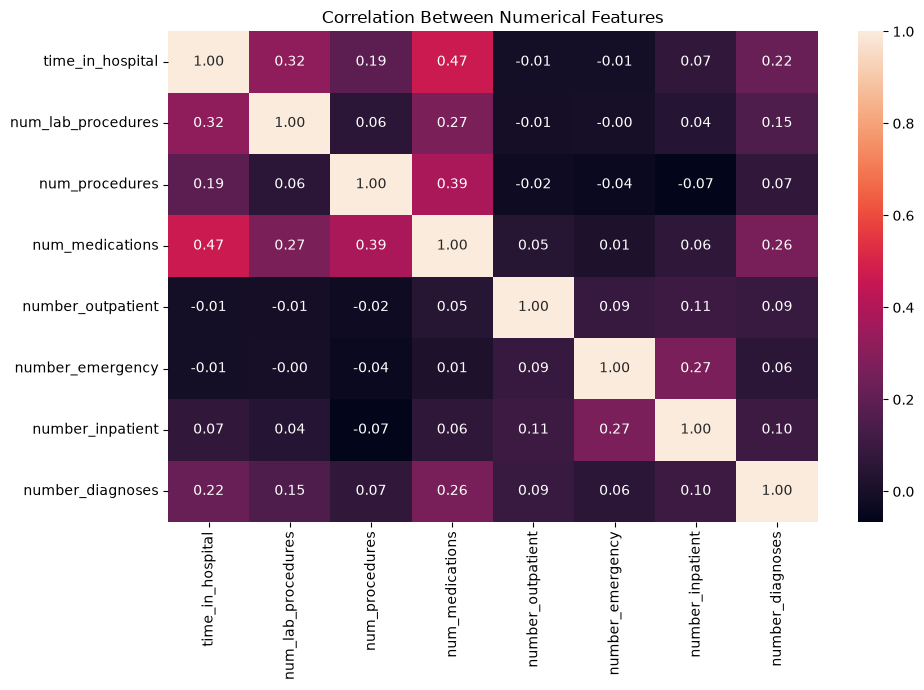

In [46]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [49]:
df["target"] = (df["readmitted"] == "<30").astype(int)
print(df["target"].mean())
print(df["patient_nbr"].nunique(), len(df))
print(df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21]).sum())

0.11159915885462728
71518 101766
2423


### EDA Summary

- Dataset contains 101,766 records and 50 columns.
- No exact duplicate rows were found.
- The target variable contains three classes: NO, >30, and <30.
- The target is moderately imbalanced, with <30 being the minority class.
- Weight has approximately 96.86% missing values and is a strong candidate for removal.
- Race has approximately 2.23% missing values.
- Payer code has approximately 39.56% missing values.
- Medical specialty has approximately 49.08% missing values.
- Age groups show differences in readmission distribution.
- Race groups show differences in readmission distribution.
- Several categorical features require encoding before model training.
- Some features contain very rare categories and will require careful preprocessing.
- Constant features such as citoglipton are candidates for removal.
